In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

In [63]:
original = pd.read_csv("../data/Mall_Customers.csv")

original.rename(columns={
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Score"
}, inplace=True)

cluster = pd.read_csv("../data/final_kmeans_output.csv")

original["Segment"] = cluster["Segment"]

df = original

df.head()

,CustomerID,Genre,Age,Income,Score,Segment
0,1,Male,19,15,39,Average Customers
1,2,Male,21,15,81,Average Customers
2,3,Female,20,16,6,Average Customers
3,4,Female,23,16,77,Average Customers
4,5,Female,31,17,40,Average Customers


**CUSTOMER SEGMENTATION FOR E-COMMERCE**


Objective

To analyze customer purchasing behavior
and segment customers into meaningful groups
using Machine Learning.

Algorithms Used

• K-Means Clustering

• DBSCAN

• PCA

• SQL Analysis

• Exploratory Data Analysis

In [64]:
print("Number of Customers :", len(df))

print("Number of Features :", len(df.columns))

print()

print(df.columns)

Number of Customers : 200
Number of Features : 6

Index(['CustomerID', 'Genre', 'Age', 'Income', 'Score', 'Segment'], dtype='str')


In [65]:
df.describe()

,CustomerID,Age,Income,Score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [66]:
segment_count = df["Segment"].value_counts()

segment_count

Segment
Young High Spenders    56
Average Customers      52
Budget Customers       38
Premium Customers      29
Regular Customers      23
Name: count, dtype: int64

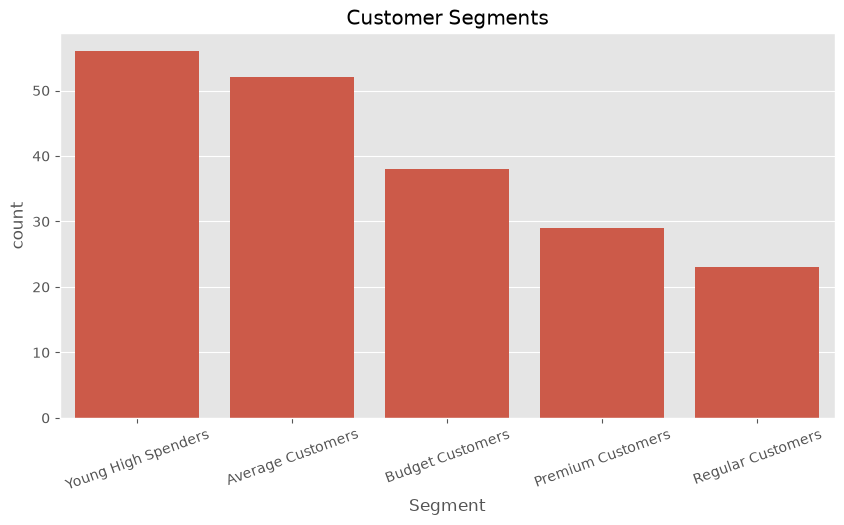

In [67]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="Segment",
    order=df["Segment"].value_counts().index
)

plt.xticks(rotation=20)

plt.title("Customer Segments")

plt.show()

In [68]:
summary = df.groupby("Segment")[["Age","Income","Score"]].mean()

summary.round(2)

,Age,Income,Score
Segment,,,
Average Customers,24.60,39.21,61.50
Budget Customers,32.76,85.21,82.11
Premium Customers,56.72,48.07,39.72
Regular Customers,39.26,88.87,16.00
Young High Spenders,47.07,55.77,37.52


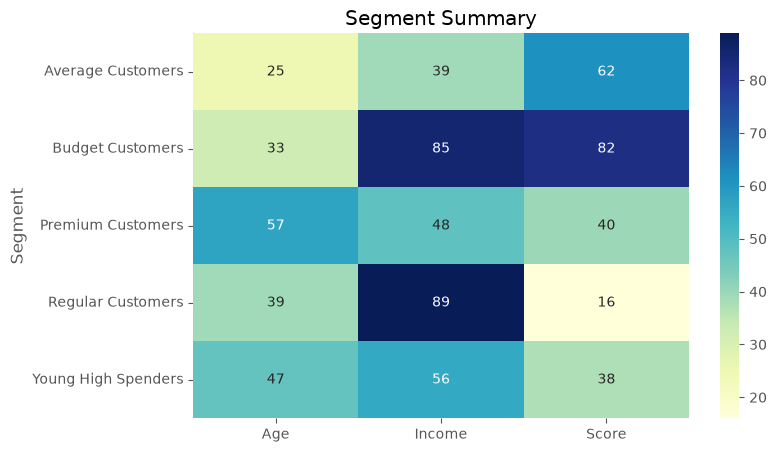

In [69]:
plt.figure(figsize=(8,5))

sns.heatmap(
    summary,
    annot=True,
    cmap="YlGnBu"
)

plt.title("Segment Summary")

plt.show()

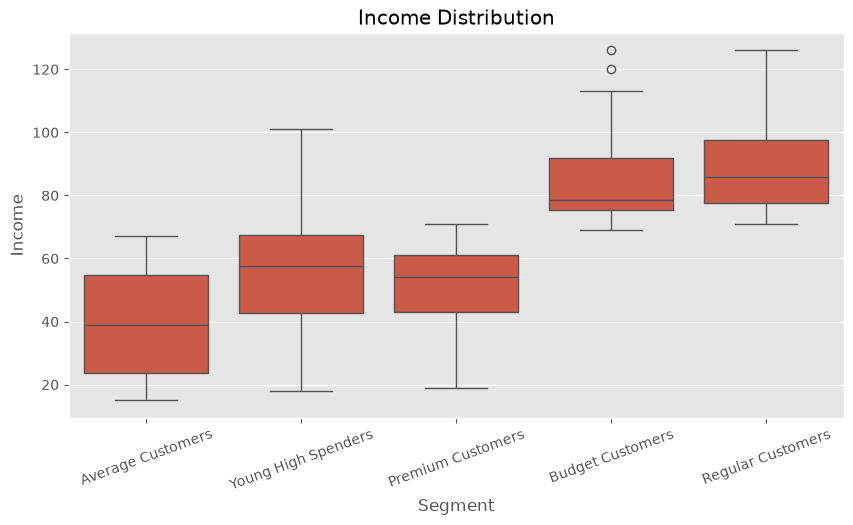

In [70]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="Segment",
    y="Income"
)

plt.title("Income Distribution")

plt.xticks(rotation=20)

plt.show()

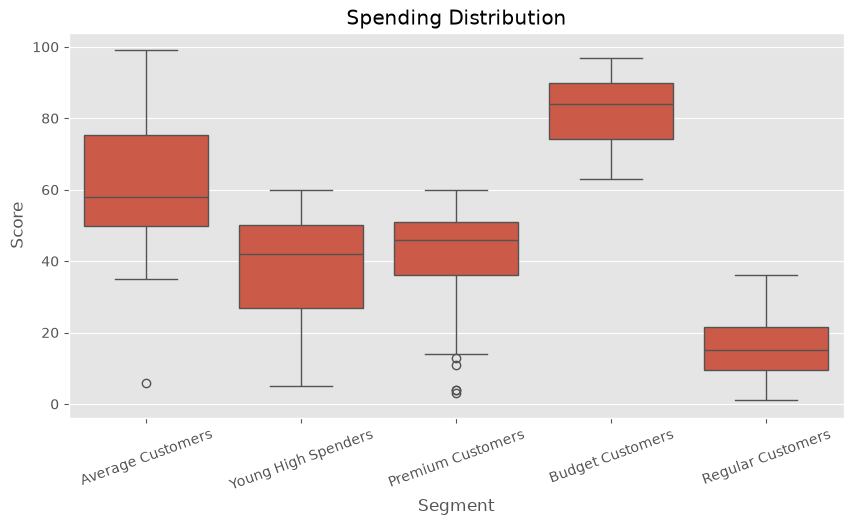

In [71]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="Segment",
    y="Score"
)

plt.title("Spending Distribution")

plt.xticks(rotation=20)

plt.show()

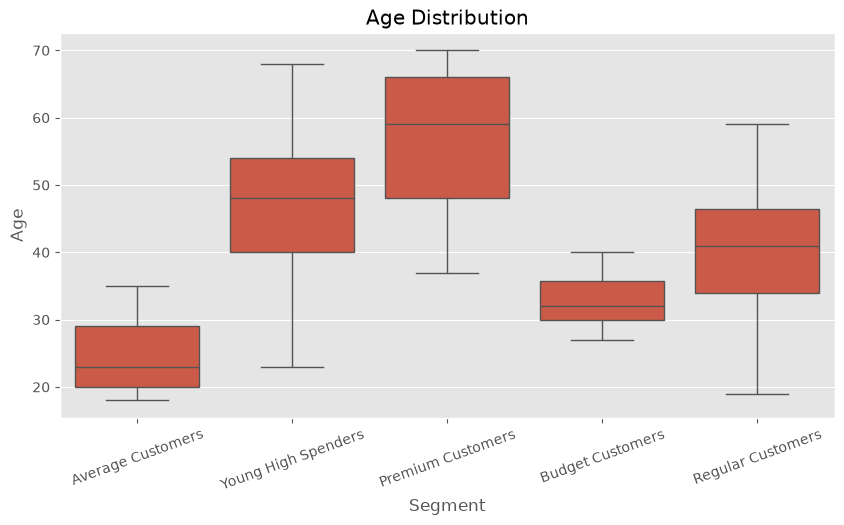

In [72]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="Segment",
    y="Age"
)

plt.title("Age Distribution")

plt.xticks(rotation=20)

plt.show()

**Correlation**

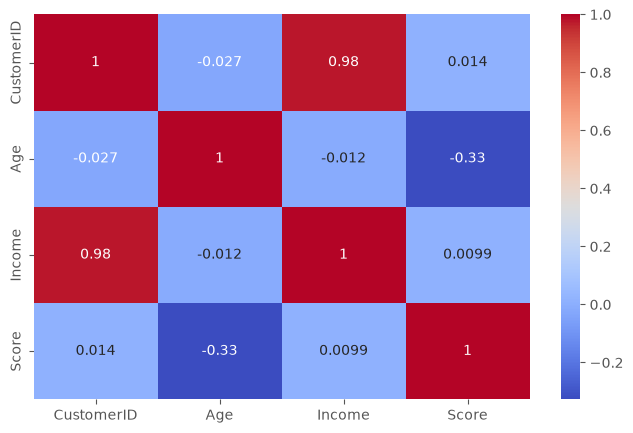

In [73]:
plt.figure(figsize=(8,5))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.show()

**KEY FINDINGS**

1. Customers naturally form distinct purchasing groups.

2. High income does not always mean high spending.

3. Some customers have moderate income but very high spending.

4. Younger customers generally spend more frequently.

5. Spending Score is one of the strongest variables for segmentation.

**Premium Customers**

Offer premium memberships,
exclusive discounts,
early product launches,
VIP services.

**Young High Spenders**

Recommend trending products,
flash sales,
social media advertisements.

**Regular Customers**

Offer loyalty rewards,
cashback,
seasonal discounts.

**Average Customers**

Increase engagement through
email campaigns and
cross-selling.

**Budget Customers**

Provide affordable products,
discount coupons,
bundle offers.


**MARKETING STRATEGY**

**Premium Customers**

✔ Premium Membership

✔ Luxury Products

✔ Exclusive Offers

-----------------------------------

**Young High Spenders**

✔ Influencer Marketing

✔ Instagram Campaigns

✔ Flash Sales

-----------------------------------

**Budget Customers**

✔ Coupons

✔ Discounts

✔ Cashback

-----------------------------------

**Average Customers**

✔ Email Marketing

✔ Personalized Offers

✔ Cross Selling

-----------------------------------

**Regular Customers**

✔ Loyalty Programs

✔ Reward Points

✔ Seasonal Offers

In [74]:
print(df.head())

print(df.shape)

print(df.describe())

   CustomerID   Genre  Age  Income  Score            Segment
0           1    Male   19      15     39  Average Customers
1           2    Male   21      15     81  Average Customers
2           3  Female   20      16      6  Average Customers
3           4  Female   23      16     77  Average Customers
4           5  Female   31      17     40  Average Customers
(200, 6)
       CustomerID         Age      Income       Score
count  200.000000  200.000000  200.000000  200.000000
mean   100.500000   38.850000   60.560000   50.200000
std     57.879185   13.969007   26.264721   25.823522
min      1.000000   18.000000   15.000000    1.000000
25%     50.750000   28.750000   41.500000   34.750000
50%    100.500000   36.000000   61.500000   50.000000
75%    150.250000   49.000000   78.000000   73.000000
max    200.000000   70.000000  137.000000   99.000000


In [77]:
dashboard = {
    "Total Customers": len(df),
    "Average Income": float(round(df["Income"].mean(), 2)),
    "Average Spending": float(round(df["Score"].mean(), 2)),
    "Average Age": float(round(df["Age"].mean(), 2))
}

print(dashboard)

{'Total Customers': 200, 'Average Income': 60.56, 'Average Spending': 50.2, 'Average Age': 38.85}


In [78]:
dashboard_df = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Average Income (k$)",
        "Average Spending Score",
        "Average Age (Years)"
    ],
    "Value": [
        len(df),
        round(df["Income"].mean(), 2),
        round(df["Score"].mean(), 2),
        round(df["Age"].mean(), 2)
    ]
})

dashboard_df

,Metric,Value
0,Total Customers,200.00
1,Average Income (k$),60.56
2,Average Spending Score,50.20
3,Average Age (Years),38.85


In [79]:
summary.to_csv(
    "../data/business_summary.csv"
)

print("Business summary exported.")

Business summary exported.


**FINAL CONCLUSION**

Customer segmentation enables businesses
to understand purchasing behavior,
identify valuable customers,
optimize marketing campaigns,
improve customer retention,
and increase revenue.

Machine learning techniques such as
K-Means and DBSCAN successfully grouped
customers into meaningful segments.

PCA simplified visualization while
preserving the majority of the information.

SQL supported efficient business analysis,
and EDA revealed patterns useful for
data-driven decision making.

**PROJECT DESCRIPTION**

Performed Exploratory Data Analysis (EDA)
on customer purchasing behavior.

Used SQL for business analysis and reporting.

Applied K-Means and DBSCAN clustering
to segment customers based on demographic
and spending patterns.

Reduced feature dimensions using PCA
to improve cluster visualization.

Generated business recommendations
to support targeted marketing
and customer retention strategies.

=================================

PROJECT COMPLETED SUCCESSFULLY

Customer Segmentation for E-commerce

=================================